# 05 · Direct vs one-stop, and which hubs to connect through
The data contains single flights, not tickets, so one-stop trips are **constructed** from real
pairs of flights on the same day (`src/connections.py`):
* *Booked:* flight A->H, then the first H->B flight of the same airline brand leaving at least
  *L* minutes after the first leg's scheduled arrival (L = the minimum-layover policy; max 5 h).
* *Realised:* the traveler makes the connection if they reach the hub 30 min before the second
  leg actually departs; otherwise they take the next completed flight of that brand.
* Cancellations are treated identically for nonstops and one-stops: next completed flight of
  the same brand on the route. Trip delay is capped at 24 h.

Brand = the airline a ticket would be bought from. Envoy/PSA fly only for American; SkyWest and
Republic fly for several brands, so each of their flights is assigned to the largest of
AA/DL/UA/AS at the busier end of the route (heuristic, stated as a limitation).

In [1]:
import sys, time
sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import prep, style, connections as cx
from style import INK, GREY, ACCENT, GOOD, BLUE, AMBER, PCT
style.use()
pd.set_option("display.width", 200, "display.max_columns", 60, "display.float_format", "{:.3f}".format)

f = cx.add_brand(pd.read_parquet(prep.PROCESSED / "flights_full.parquet"))
comp = cx.completed_table(f)
air = pd.read_parquet(prep.PROCESSED / "airports_enriched.parquet").set_index("airport")
vol = f.groupby("ORIGIN", observed=True).size().sort_values(ascending=False)
AIRPORTS = vol.index[:60].astype(str).tolist()          # markets between the 60 busiest airports
HUBS = vol.index[:20].astype(str).tolist()               # 20 busiest airports as candidate hubs
pd.crosstab(f.CARRIER, f.brand)

brand,AA,AS,B6,DL,OO,UA,WN
CARRIER,,,,,,,
AA,973653,0,0,0,0,0,0
AS,0,245588,0,0,0,0,0
B6,0,0,231413,0,0,0,0
DL,0,0,0,1026332,0,0,0
MQ,299322,0,0,0,0,0,0
OH,248735,0,0,0,0,0,0
OO,112697,82648,0,274590,328,369558,0
UA,0,0,0,0,0,795271,0
WN,0,0,0,0,0,0,1391885


## 1. Every flight as a trip: nonstop outcomes with cancellations rebooked

In [2]:
ns = cx.nonstop_realised(f, comp)
f = pd.concat([f, ns], axis=1)
f[["route", "brand", "sched_dep", "dep_hour", "MONTH", "DAY_OF_WEEK", "time_band", "CRS_ELAPSED_TIME", "completed", "CANCELLED", "trip_delay", "rebooked", "overnight", "disrupted", "severe", "late_night_arrival", "early_dep", "long_wait"]].to_parquet(prep.PROCESSED / "nonstop_trips.parquet", index=False)
print(f"nonstop trips: severe (60+ min late incl. rebooked cancellations) {(f.trip_delay >= 60).mean():.1%}; "
      f"overnight stranding {f.overnight.mean():.2%}; mean rebooking delay after a cancellation {f.loc[f.rebooked == 1, 'trip_delay'].mean() / 60:.1f} h")

nonstop trips: severe (60+ min late incl. rebooked cancellations) 9.6%; overnight stranding 1.42%; mean rebooking delay after a cancellation 10.2 h


## 2. Build one-stop itineraries under four minimum-layover policies

In [3]:
tr = cx.pick_triples(f, HUBS, AIRPORTS)
print(f"{tr.groupby(['ORIGIN', 'DEST']).ngroups} markets with nonstop service, {len(tr)} market-hub combinations")
runs = []
for L in [45, 60, 90, 120]:
    t = time.time()
    it = cx.build_itineraries(f, comp, tr, min_layover=L, mct=30, frac=0.2)
    runs.append(it); print(f"L={L}: {len(it):,} itineraries in {time.time() - t:.0f}s")
it = pd.concat(runs, ignore_index=True)
it.to_parquet(prep.PROCESSED / "onestop_itineraries.parquet", index=False)

1730 markets with nonstop service, 10142 market-hub combinations


L=45: 3,400,188 itineraries in 27s


L=60: 3,236,200 itineraries in 27s


L=90: 2,868,316 itineraries in 26s


L=120: 2,617,761 itineraries in 27s


## 3. Nonstop vs one-stop on the same markets
Nonstop flights are restricted to the same markets, and both are compared by departure time band.

In [4]:
mk = tr[["ORIGIN", "DEST"]].drop_duplicates()
nsm = f.assign(ORIGIN=f.ORIGIN.astype(str), DEST=f.DEST.astype(str)).merge(mk, on=["ORIGIN", "DEST"])
nsm["kind"] = "Nonstop"; nsm["sched_total"] = nsm.CRS_ELAPSED_TIME
ORDER = ["Nonstop"] + [f"One-stop, min layover {L} min" for L in [45, 60, 90, 120]]
it["kind"] = "One-stop, min layover " + it.min_layover.astype(str) + " min"
cols = ["kind", "trip_delay", "overnight", "sched_total", "dep_hour", "MONTH"]
both = pd.concat([nsm[cols], it[cols]], ignore_index=True)
summ = cx.trip_metrics(both, "kind")
summ["sched_hours"] = both.groupby("kind").sched_total.mean() / 60
summ["misconnect"] = it.groupby("kind").misconnect.mean()
summ["avg_layover"] = it.groupby("kind").layover.mean()
summ = summ.reindex(ORDER)
summ.to_csv(prep.TABLES / "nonstop_vs_onestop.csv")
summ

,n,disrupted,severe,delay_3h,overnight,exp_delay_min,p90_delay,sched_hours,misconnect,avg_layover
kind,,,,,,,,,,
Nonstop,3322999,0.237,0.094,0.027,0.013,24.711,55.000,3.004,NaN,NaN
"One-stop, min layover 45 min",3400188,0.322,0.161,0.068,0.037,51.764,115.000,7.054,0.051,119.855
"One-stop, min layover 60 min",3236200,0.313,0.150,0.059,0.032,46.696,101.000,7.302,0.038,135.035
"One-stop, min layover 90 min",2868316,0.304,0.136,0.047,0.025,39.762,85.000,7.834,0.023,168.638
"One-stop, min layover 120 min",2617761,0.301,0.130,0.042,0.023,36.780,80.000,8.190,0.016,191.641


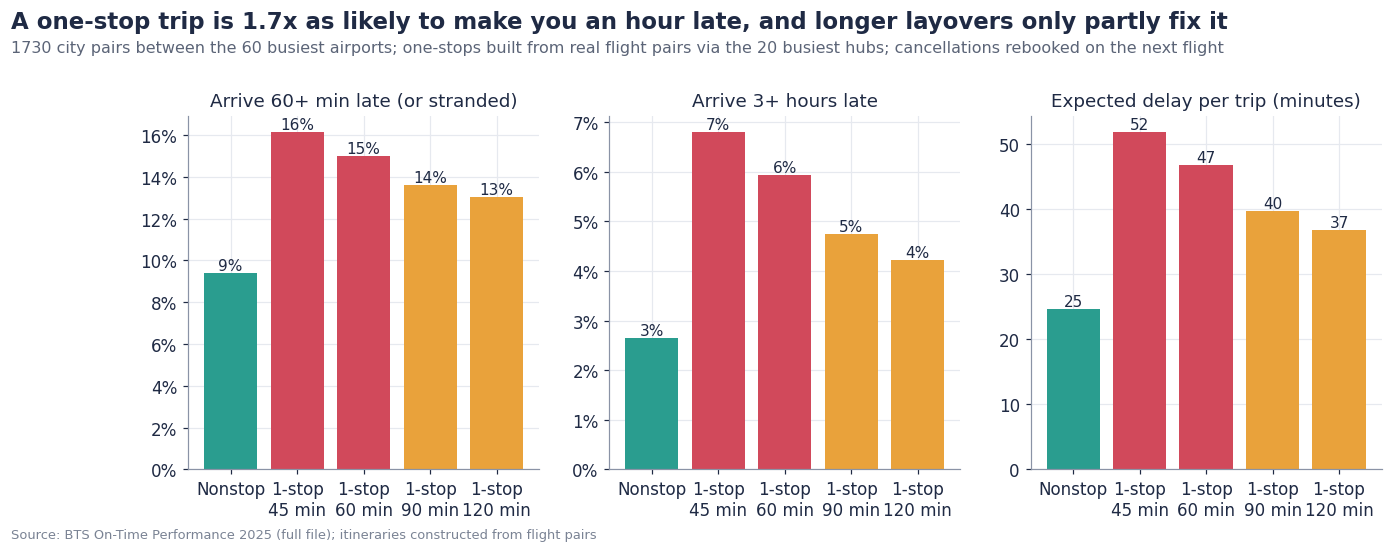

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.8))
lab = ["Nonstop", "1-stop\n45 min", "1-stop\n60 min", "1-stop\n90 min", "1-stop\n120 min"]
cols_ = [GOOD, ACCENT, ACCENT, AMBER, AMBER]
for ax, m, ttl, fmt in zip(axes, ["severe", "delay_3h", "exp_delay_min"],
                           ["Arrive 60+ min late (or stranded)", "Arrive 3+ hours late", "Expected delay per trip (minutes)"], [PCT, PCT, None]):
    ax.bar(lab, summ[m], color=cols_)
    for i, v in enumerate(summ[m]):
        ax.text(i, v, f"{v:.0%}" if fmt else f"{v:.0f}", ha="center", va="bottom", fontsize=10)
    if fmt: ax.yaxis.set_major_formatter(fmt)
    ax.set_title(ttl, fontsize=12, loc="center", fontweight="normal")
fig.suptitle(f"A one-stop trip is {summ.severe.iloc[1] / summ.severe.iloc[0]:.1f}x as likely to make you an hour late, and longer layovers only partly fix it",
             x=0.01, ha="left", fontsize=15, fontweight="bold", color=INK)
fig.text(0.01, 0.9, f"{tr.groupby(['ORIGIN', 'DEST']).ngroups} city pairs between the 60 busiest airports; one-stops built from real flight pairs via the 20 busiest hubs; cancellations rebooked on the next flight", fontsize=10.5, color="#5B6477")
fig.subplots_adjust(top=0.78)
style.save(fig, "17_nonstop_vs_onestop", "Source: BTS On-Time Performance 2025 (full file); itineraries constructed from flight pairs");

## 4. Minimum layover: how much buffer does a connection need?

,n,disrupted,severe,delay_3h,overnight,exp_delay_min,p90_delay,misconnect,avg_layover
min_layover,,,,,,,,,
45,3400188,0.322,0.161,0.068,0.037,51.764,115.000,0.051,119.855
60,3236200,0.313,0.150,0.059,0.032,46.696,101.000,0.038,135.035
90,2868316,0.304,0.136,0.047,0.025,39.762,85.000,0.023,168.638
120,2617761,0.301,0.130,0.042,0.023,36.780,80.000,0.016,191.641


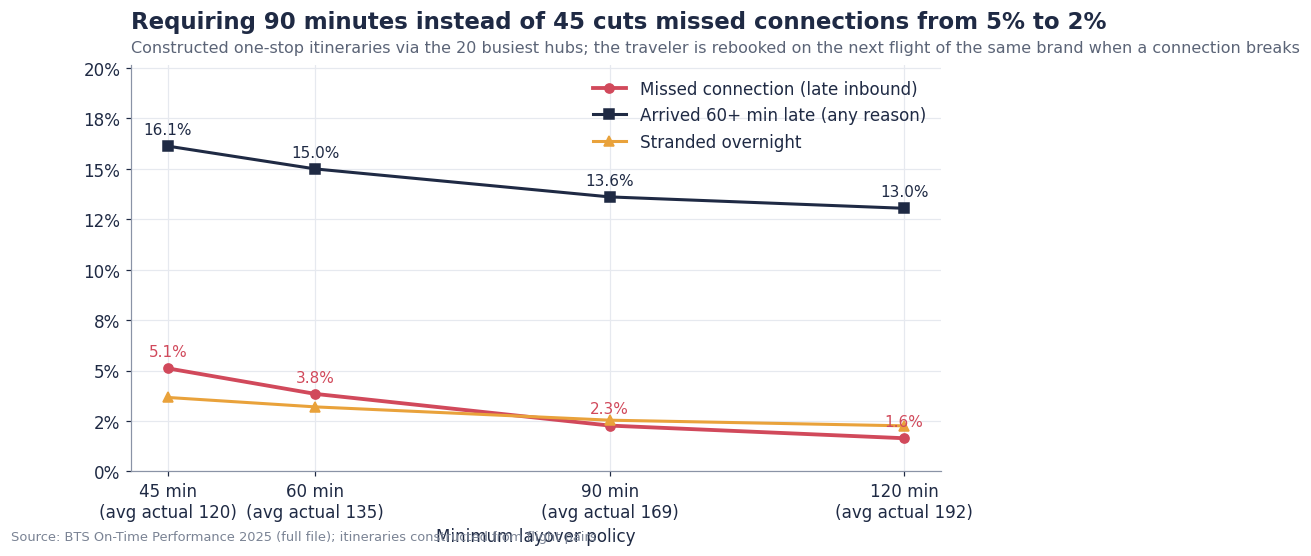

In [6]:
lay = cx.trip_metrics(it, ["min_layover", "HUB"])
lay["misconnect"] = it.groupby(["min_layover", "HUB"], observed=True).misconnect.mean()
lay["layover"] = it.groupby(["min_layover", "HUB"], observed=True).layover.mean()
curve = cx.trip_metrics(it, "min_layover"); curve["misconnect"] = it.groupby("min_layover").misconnect.mean(); curve["avg_layover"] = it.groupby("min_layover").layover.mean()
curve.to_csv(prep.TABLES / "layover_curve.csv")
fig, ax = plt.subplots(figsize=(9.5, 4.8))
ax.plot(curve.index, curve.misconnect, marker="o", color=ACCENT, lw=2.5, label="Missed connection (late inbound)")
ax.plot(curve.index, curve.severe, marker="s", color=INK, lw=2, label="Arrived 60+ min late (any reason)")
ax.plot(curve.index, curve.overnight, marker="^", color=AMBER, lw=2, label="Stranded overnight")
for x, y in zip(curve.index, curve.misconnect): ax.text(x, y + .006, f"{y:.1%}", ha="center", color=ACCENT, fontsize=10)
for x, y in zip(curve.index, curve.severe): ax.text(x, y + .006, f"{y:.1%}", ha="center", color=INK, fontsize=10)
ax.set_xticks(curve.index); ax.set_xticklabels([f"{x} min\n(avg actual {a:.0f})" for x, a in zip(curve.index, curve.avg_layover)])
ax.yaxis.set_major_formatter(PCT); ax.set_xlabel("Minimum layover policy"); ax.set_ylim(0, curve.severe.max() * 1.25); ax.legend(loc="upper right")
style.titled(ax, f"Requiring 90 minutes instead of 45 cuts missed connections from {curve.misconnect[45]:.0%} to {curve.misconnect[90]:.0%}",
             "Constructed one-stop itineraries via the 20 busiest hubs; the traveler is rebooked on the next flight of the same brand when a connection breaks")
style.save(fig, "18_layover_curve", "Source: BTS On-Time Performance 2025 (full file); itineraries constructed from flight pairs");
curve

## 5. Ranking the connecting hubs (60-minute minimum layover policy)

,name,n,markets,misconnect,severe,overnight,exp_delay_min,layover,winter_fragility_pts,dominant_carrier,dominant_carrier_share
HUB,,,,,,,,,,,
SLC,Salt Lake City International Airport,101866,534,0.030,0.094,0.020,33.225,142.434,0.183,DL,0.486
LAX,Los Angeles International Airport,116280,416,0.028,0.100,0.019,31.432,146.704,NaN,OO,0.231
SEA,Seattle–Tacoma International Airport,54800,198,0.029,0.101,0.019,36.548,143.241,0.111,AS,0.469
LAS,Harry Reid International Airport,118736,570,0.023,0.108,0.017,31.098,143.252,NaN,WN,0.592
SFO,San Francisco International Airport,90714,328,0.041,0.109,0.017,33.794,136.170,NaN,UA,0.414
PHX,Phoenix Sky Harbor International Airport,160359,510,0.033,0.116,0.025,39.922,145.014,NaN,WN,0.363
MSP,Minneapolis–Saint Paul International Airport /...,103804,546,0.032,0.122,0.028,39.631,146.012,0.283,DL,0.597
IAH,George Bush Intercontinental Airport,145635,592,0.036,0.135,0.033,45.314,124.862,0.395,UA,0.681
DTW,Detroit Metropolitan Wayne County Airport,134865,736,0.033,0.136,0.029,42.601,153.659,0.236,DL,0.544


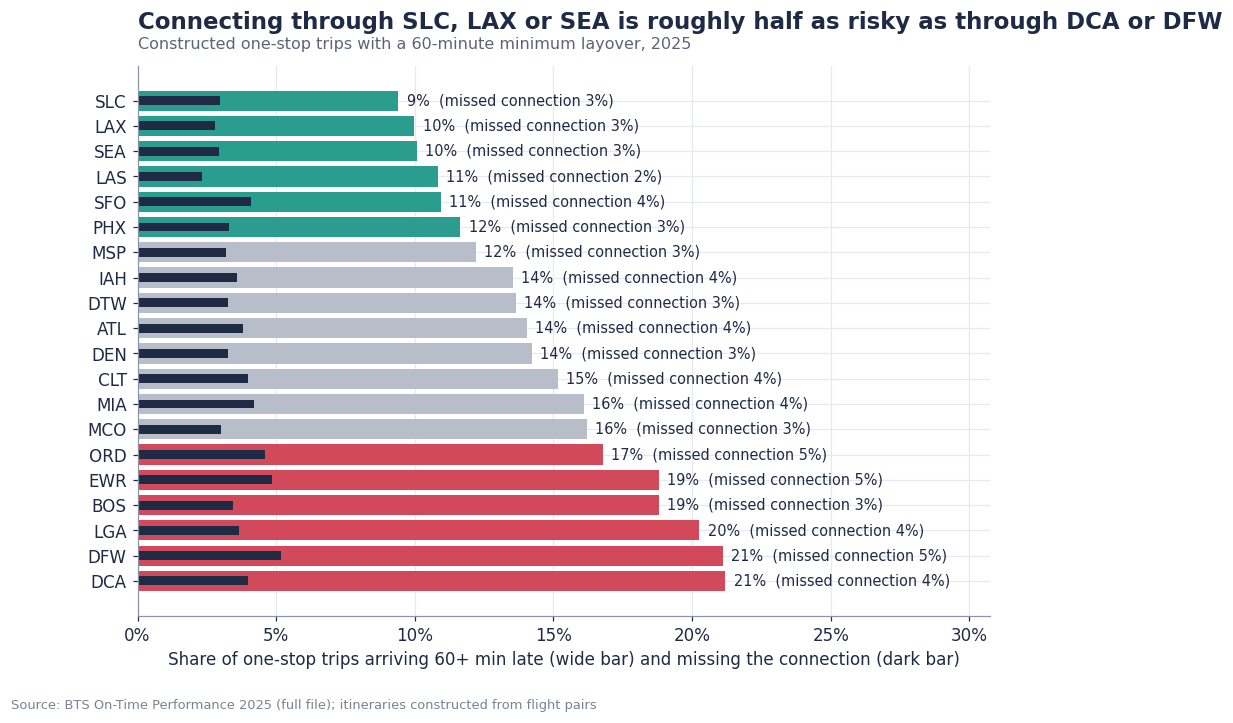

In [7]:
hub = lay.xs(60, level="min_layover").copy()
hub["markets"] = tr.groupby("HUB").apply(lambda d: d[["ORIGIN", "DEST"]].drop_duplicates().shape[0], include_groups=False)
hub = hub.join(air[["name", "runways", "destinations", "dominant_carrier", "dominant_carrier_share"]])
wr = pd.read_csv(prep.TABLES / "winter_readiness.csv", index_col=0)
hub["winter_fragility_pts"] = wr.uplift_pts
hub = hub.sort_values("severe")
hub.to_csv(prep.TABLES / "hub_ranking.csv")
fig, ax = plt.subplots(figsize=(10, 6.5))
y = np.arange(len(hub))
ax.barh(y, hub.severe, color=[GOOD if v < hub.severe.quantile(.3) else (ACCENT if v > hub.severe.quantile(.7) else GREY) for v in hub.severe])
ax.barh(y, hub.misconnect, color=INK, height=.35)
for i, (s, m, n) in enumerate(zip(hub.severe, hub.misconnect, hub.n)):
    ax.text(s + .003, i, f"{s:.0%}  (missed connection {m:.0%})", va="center", fontsize=9.5)
ax.set_yticks(y); ax.set_yticklabels(hub.index); ax.invert_yaxis(); ax.xaxis.set_major_formatter(PCT); ax.set_xlim(0, hub.severe.max() * 1.45)
ax.set_xlabel("Share of one-stop trips arriving 60+ min late (wide bar) and missing the connection (dark bar)")
style.titled(ax, f"Connecting through {hub.index[0]}, {hub.index[1]} or {hub.index[2]} is roughly half as risky as through {hub.index[-1]} or {hub.index[-2]}",
             "Constructed one-stop trips with a 60-minute minimum layover, 2025")
style.save(fig, "19_hub_ranking", "Source: BTS On-Time Performance 2025 (full file); itineraries constructed from flight pairs");
hub[["name", "n", "markets", "misconnect", "severe", "overnight", "exp_delay_min", "layover", "winter_fragility_pts", "dominant_carrier", "dominant_carrier_share"]]

## 6. Season and time of day for connections

In [8]:
it60 = it[it.min_layover == 60]
seas = cx.trip_metrics(it60.assign(season=it60.MONTH.map({12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring", 6: "Summer", 7: "Summer", 8: "Summer", 9: "Fall", 10: "Fall", 11: "Fall"})), "season")
seas["misconnect"] = it60.groupby(it60.MONTH.map({12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring", 6: "Summer", 7: "Summer", 8: "Summer", 9: "Fall", 10: "Fall", 11: "Fall"})).misconnect.mean()
band = pd.cut(it60.dep_hour, [-1, 9, 13, 17, 24], labels=["Depart before 10a", "10a-1:59p", "2-5:59p", "6p or later"])
tod = cx.trip_metrics(it60.assign(band=band), "band"); tod["misconnect"] = it60.groupby(band, observed=True).misconnect.mean()
pd.concat({"season": seas, "first-leg departure": tod})[["n", "misconnect", "severe", "overnight", "exp_delay_min"]]

n  misconnect  severe  overnight  exp_delay_min
season              Fall                800932       0.033   0.121      0.025         37.828
                    Spring              843782       0.037   0.136      0.027         39.928
                    Summer              842502       0.047   0.203      0.044         59.706
                    Winter              748984       0.036   0.138      0.031         49.171
first-leg departure Depart before 10a  1347977       0.024   0.115      0.011         32.326
                    10a-1:59p           920902       0.034   0.164      0.032         46.436
                    2-5:59p             699055       0.060   0.194      0.068         67.833
                    6p or later         268266       0.068   0.163      0.046         64.719

## 7. When is a one-stop worth it? Break-even fare saving
No fares are in the data, so the question is turned around: **how much cheaper must the one-stop
be to pay for its extra time?** Extra time = longer schedule + higher expected delay, valued at a
loaded hourly cost of the traveler's time (assumption: $50 / $100 / $150 per hour). A missed
meeting is valued separately as a sensitivity.

In [9]:
per_mkt_ns = nsm.groupby(["ORIGIN", "DEST"]).agg(n_ns=("trip_delay", "size"), sched_ns=("sched_total", "mean"), delay_ns=("trip_delay", lambda s: s.clip(lower=0).mean()), severe_ns=("trip_delay", lambda s: (s >= 60).mean()))
it90 = it[it.min_layover == 90]
per_mkt_os = it90.groupby(["ORIGIN", "FINAL"]).agg(n_os=("trip_delay", "size"), sched_os=("sched_total", "mean"), delay_os=("trip_delay", lambda s: s.clip(lower=0).mean()), severe_os=("trip_delay", lambda s: (s >= 60).mean()))
per_mkt_os.index.names = ["ORIGIN", "DEST"]
be = per_mkt_ns.join(per_mkt_os, how="inner")
be = be[(be.n_ns >= 300) & (be.n_os >= 300)]
be["extra_hours"] = ((be.sched_os - be.sched_ns) + (be.delay_os - be.delay_ns)) / 60
be["extra_severe_pts"] = be.severe_os - be.severe_ns
for rate in [50, 100, 150]:
    be[f"breakeven_${rate}/h"] = be.extra_hours * rate
be["breakeven_$100/h_plus_$500_meeting"] = be.extra_hours * 100 + be.extra_severe_pts * 500
be = be.sort_values("n_ns", ascending=False)
be.to_csv(prep.TABLES / "breakeven_by_market.csv")
summary = be[["extra_hours", "extra_severe_pts", "breakeven_$50/h", "breakeven_$100/h", "breakeven_$150/h", "breakeven_$100/h_plus_$500_meeting"]].describe().loc[["25%", "50%", "75%"]]
print(f"{len(be)} markets. Typical one-stop (90-min layover) costs {be.extra_hours.median():.1f} extra hours per trip and adds {be.extra_severe_pts.median():.1%} pts to the chance of being an hour late.")
summary

1598 markets. Typical one-stop (90-min layover) costs 4.3 extra hours per trip and adds 4.9% pts to the chance of being an hour late.


,extra_hours,extra_severe_pts,breakeven_$50/h,breakeven_$100/h,breakeven_$150/h,breakeven_$100/h_plus_$500_meeting
25%,4.067,0.030,203.363,406.725,610.088,425.024
50%,4.331,0.049,216.546,433.092,649.638,457.974
75%,4.563,0.071,228.164,456.328,684.492,487.116


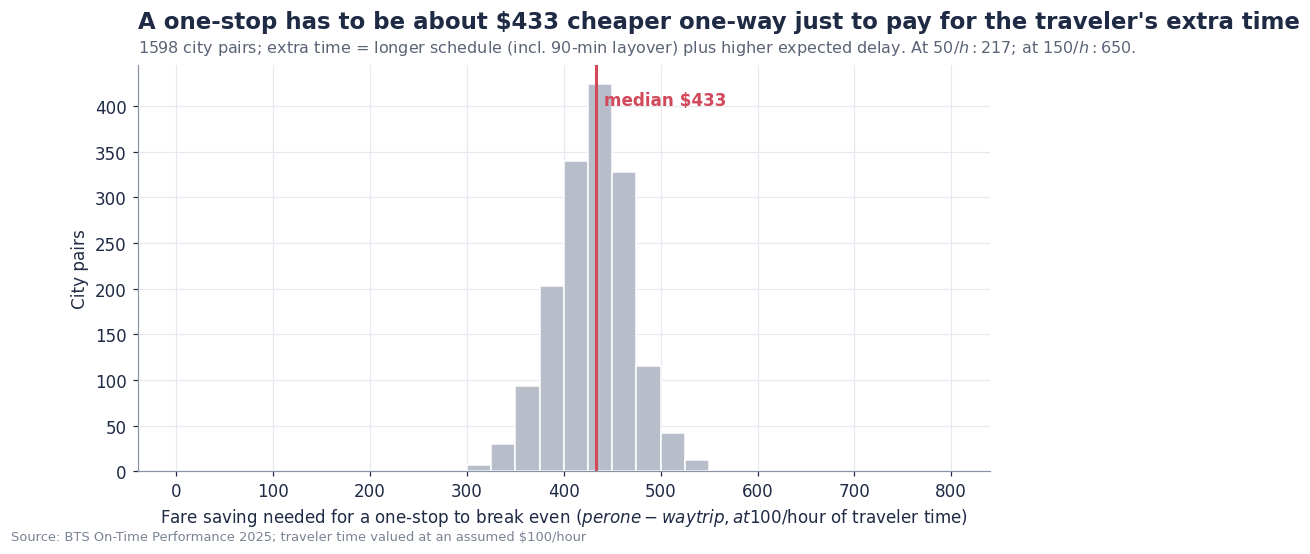

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.hist(be["breakeven_$100/h"].clip(upper=800), bins=np.arange(0, 820, 25), color=GREY, edgecolor="white")
med = be["breakeven_$100/h"].median()
ax.axvline(med, color=ACCENT, lw=2); ax.text(med + 8, ax.get_ylim()[1] * .9, f"median ${med:.0f}", color=ACCENT, fontweight="bold")
ax.set_xlabel("Fare saving needed for a one-stop to break even ($ per one-way trip, at $100/hour of traveler time)"); ax.set_ylabel("City pairs")
style.titled(ax, f"A one-stop has to be about ${med:.0f} cheaper one-way just to pay for the traveler's extra time",
             f"{len(be)} city pairs; extra time = longer schedule (incl. 90-min layover) plus higher expected delay. At $50/h: ${be['breakeven_$50/h'].median():.0f}; at $150/h: ${be['breakeven_$150/h'].median():.0f}.")
style.save(fig, "20_breakeven_fare", "Source: BTS On-Time Performance 2025; traveler time valued at an assumed $100/hour");

## Takeaways
* On the same city pairs, a one-stop trip is roughly twice as likely as a nonstop to arrive an
  hour late, and several times as likely to leave the traveler stranded overnight.
* A 90-minute minimum layover removes most missed connections; 45 minutes is a gamble.
* Hubs differ two-fold in connection risk; the ranking feeds the "approved hubs" list.
* A one-stop needs to be roughly $100-200 cheaper one-way to pay for the traveler's extra time -
  before counting the cost of a missed meeting.

**Limitations:** constructed itineraries, not tickets sold; 30-min connection assumption; the
rebooked traveler is assumed to get a seat on the next flight (optimistic on bad days); brand
assignment for SkyWest/Republic is a heuristic; connection risk ignores terminal changes.